<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# An observation ending is not a device failure

Estimate a Kaplan–Meier curve from right-censored follow-up records, reconcile it with visible SQL risk-set arithmetic, and see what changes when observation stops earlier. The question is why subtracting observed failures from the original cohort can differ from a time-to-event estimate—and why a median can remain unreached.

**All 24 devices and times are invented.** The fixed input deliberately includes tied failures and censoring. It is neither a field reliability sample nor clinical data. Times are days after a shared synthetic origin, not calendar dates. No population inference or device reliability guarantee is intended.

## Choose the administrative observation cutoff

`FOLLOWUP_DAYS` accepts an integer from **1 to 22**, default **16**. The experiment uses **8**. SQL shortens each recorded duration to this cutoff; an event remains observed only if it occurred at or before the cutoff. A failure after the cutoff becomes censored at the cutoff. Earlier censoring remains censoring. Restart and run all after editing.

In [1]:
FOLLOWUP_DAYS = 16

In [2]:
import hashlib
import json
import math
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from notebook_support import finish, theme

assert isinstance(FOLLOWUP_DAYS, int) and not isinstance(FOLLOWUP_DAYS, bool) and 1 <= FOLLOWUP_DAYS <= 22
manifest = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256(Path("fixtures/followup.csv").read_bytes()).hexdigest() == manifest["sha256"]
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-survival/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-survival/notebooks/pyproject.toml.

## Launch the pinned public worker and build the observed relation

The literal `uvx` command fetches a published Git revision and pins the tested lifelines/SDK dependencies. No checkout worker or local source import is used. The event convention is explicit: **1 = failure observed**, **0 = right-censored**. The estimator receives only duration and event; identifiers and future recorded follow-up are excluded.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'survival' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with lifelines==0.30.3 --with numpy==2.5.4 --with pandas==2.3.3 --with scipy==1.18.1 --from git+https://github.com/Query-farm/vgi-survival@97c18e976e2d4783cb846c41269a42e8febdb869 vgi-survival-worker');
CREATE TABLE recorded AS SELECT * FROM read_csv('fixtures/followup.csv',header=true,
 columns={'device_id':'VARCHAR','recorded_days':'INTEGER','recorded_event':'INTEGER'});
CREATE TABLE cohort AS SELECT device_id,least(recorded_days,{{ FOLLOWUP_DAYS }}) AS duration_days,
 (recorded_event=1 AND recorded_days<={{ FOLLOWUP_DAYS }})::INTEGER AS event,
 recorded_days>{{ FOLLOWUP_DAYS }} AS administratively_shortened
FROM recorded;

,Count


In [4]:
%%sql availability <<
SELECT count(*) AS devices,sum(event) AS observed_failures,count(*)-sum(event) AS censored,
 count(*) FILTER(WHERE administratively_shortened) AS shortened,
 min(duration_days) AS first_exit_day,max(duration_days) AS last_exit_day FROM cohort;

In [5]:
display(availability)

,devices,observed_failures,censored,shortened,first_exit_day,last_exit_day
0,24,13.0,11.0,4,2,16


## Estimate the curve and median through VGI

Each table function buffers the whole projected cohort before estimating. We materialize each call once, then use local tables for displays and plots. The worker returns a step curve, at-risk counts, and lifelines’ default **95% pointwise confidence bounds**. These bounds are estimator output for the invented dataset; they are not calibrated evidence about a real device population.

Right-censoring means the event time is not observed beyond that follow-up time. Generalizing a Kaplan–Meier estimate requires assumptions such as censoring independent of the event process; changing a label in this example cannot establish that assumption. There is no left truncation or competing event here.

In [6]:
%%sql
CREATE TABLE km AS SELECT * FROM survival.main.kaplan_meier(
 (SELECT duration_days,event FROM cohort),duration:='duration_days',event:='event');
CREATE TABLE estimated_median AS SELECT * FROM survival.main.median_survival(
 (SELECT duration_days,event FROM cohort),duration:='duration_days',event:='event');

,Count


## Reconcile risk sets and the product-limit formula

At each observed time, the risk set contains everyone whose follow-up reaches that time. Tied events and censoring are included in that starting count; failures reduce survival, while censoring changes later denominators. SQL computes the product of **(1 − failures / at risk)** and compares it with the worker. If a factor reaches zero, all subsequent survival values remain zero.

The dashed comparator is `1 − cumulative observed failures / original N`. It treats people with unobserved later outcomes as if they still contributed to that original denominator. It is displayed to expose the distinction, not presented as an alternative censoring estimator.

In [7]:
%%sql
CREATE TABLE event_table AS
WITH timeline AS (SELECT 0 AS time UNION SELECT duration_days FROM cohort)
SELECT t.time,count(*) FILTER(WHERE c.duration_days>=t.time) AS at_risk_sql,
 count(*) FILTER(WHERE c.duration_days=t.time AND c.event=1) AS failures,
 count(*) FILTER(WHERE c.duration_days=t.time AND c.event=0) AS censored
FROM timeline t CROSS JOIN cohort c GROUP BY t.time;
CREATE TABLE comparison AS
WITH factors AS (SELECT *,1.0-failures::DOUBLE/at_risk_sql AS factor FROM event_table),
 product_limit AS (
 SELECT *,CASE WHEN sum((factor=0)::INTEGER) OVER(ORDER BY time)>0 THEN 0.0
 ELSE exp(sum(ln(nullif(factor,0))) OVER(ORDER BY time)) END AS survival_sql,
 1.0-sum(failures) OVER(ORDER BY time)/(SELECT count(*)::DOUBLE FROM cohort) AS original_denominator
 FROM factors
)
SELECT k.*,p.at_risk_sql,p.failures,p.censored,p.survival_sql,p.original_denominator
FROM km k JOIN product_limit p USING(time);
CREATE TABLE median_check AS SELECT m.median_survival,
 coalesce((SELECT min(time) FROM km WHERE survival<=0.5),'Infinity'::DOUBLE) AS first_half_crossing
FROM estimated_median m;

,Count


In [8]:
%%sql curve <<
SELECT * FROM comparison ORDER BY time;

In [9]:
%%sql median <<
SELECT * FROM median_check;

,time,survival,ci_lower,ci_upper,at_risk,at_risk_sql,failures,censored,survival_sql,original_denominator
0,0.0,1.000000,1.000000,1.000000,24,24,0,0,1.000000,1.000000
1,2.0,0.958333,0.739206,0.994024,24,24,1,0,0.958333,0.958333
2,3.0,0.916667,0.706055,0.978483,23,23,1,0,0.916667,0.916667
3,4.0,0.875000,0.660755,0.957882,22,22,1,1,0.875000,0.875000
4,5.0,0.831250,0.610370,0.933146,20,20,1,0,0.831250,0.833333
5,6.0,0.743750,0.515815,0.875996,19,19,2,1,0.743750,0.750000
6,7.0,0.697266,0.466773,0.843112,16,16,1,0,0.697266,0.708333
7,8.0,0.650781,0.420128,0.808317,15,15,1,1,0.650781,0.666667
8,9.0,0.600721,0.370337,0.769929,13,13,1,0,0.600721,0.625000
9,10.0,0.550661,0.323365,0.729564,12,12,1,1,0.550661,0.583333


,median_survival,first_half_crossing
0,12.0,12.0


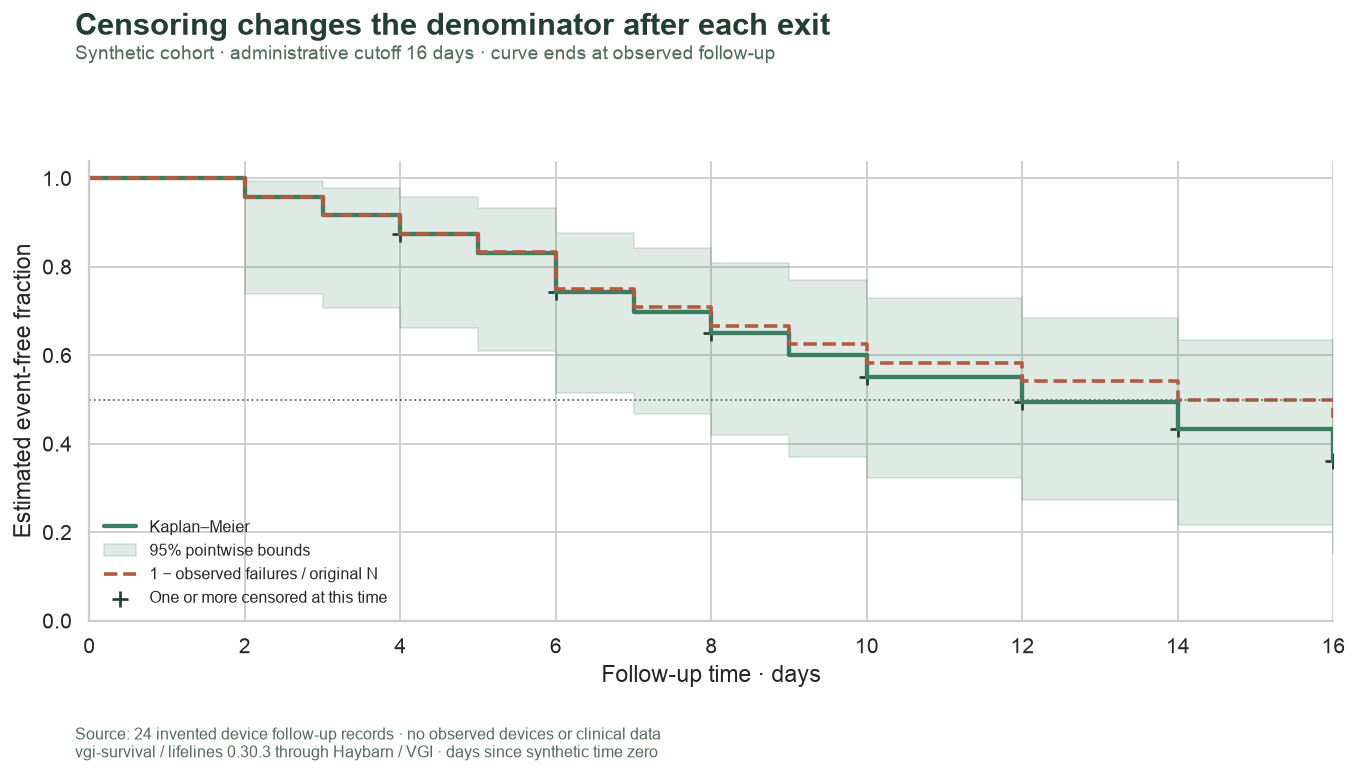

In [10]:
display(curve)
display(median)
fig, ax = plt.subplots(figsize=(11, 6))
ax.step(curve.time, curve.survival, where="post", linewidth=2.4, color="#397d62", label="Kaplan–Meier")
ax.fill_between(
    curve.time, curve.ci_lower, curve.ci_upper, step="post", color="#397d62", alpha=0.16, label="95% pointwise bounds"
)
ax.step(
    curve.time,
    curve.original_denominator,
    where="post",
    linestyle="--",
    linewidth=2,
    color="#b25b3f",
    label="1 − observed failures / original N",
)
censored_times = curve.loc[curve.censored > 0]
ax.scatter(
    censored_times.time,
    censored_times.survival,
    marker="+",
    s=70,
    color="#243e32",
    label="One or more censored at this time",
)
ax.axhline(0.5, color="#526b5b", linewidth=1, linestyle=":")
ax.set(xlabel="Follow-up time · days", ylabel="Estimated event-free fraction", xlim=(0, FOLLOWUP_DAYS), ylim=(0, 1.04))
ax.legend(loc="lower left", frameon=False, fontsize=9)
finish(
    fig,
    f"survival-{FOLLOWUP_DAYS}",
    "Censoring changes the denominator after each exit",
    f"Synthetic cohort · administrative cutoff {FOLLOWUP_DAYS} days · curve ends at observed follow-up",
)

## Inspect the information supporting each step

The upper panel shows the risk set **just before** each observed time, including the time-zero baseline. The lower panel counts failures and censoring at each exit time. A censor mark at the cutoff can represent multiple devices; it does not mean a failure occurred there. Connecting risk-set markers is only a visual guide between observed times.

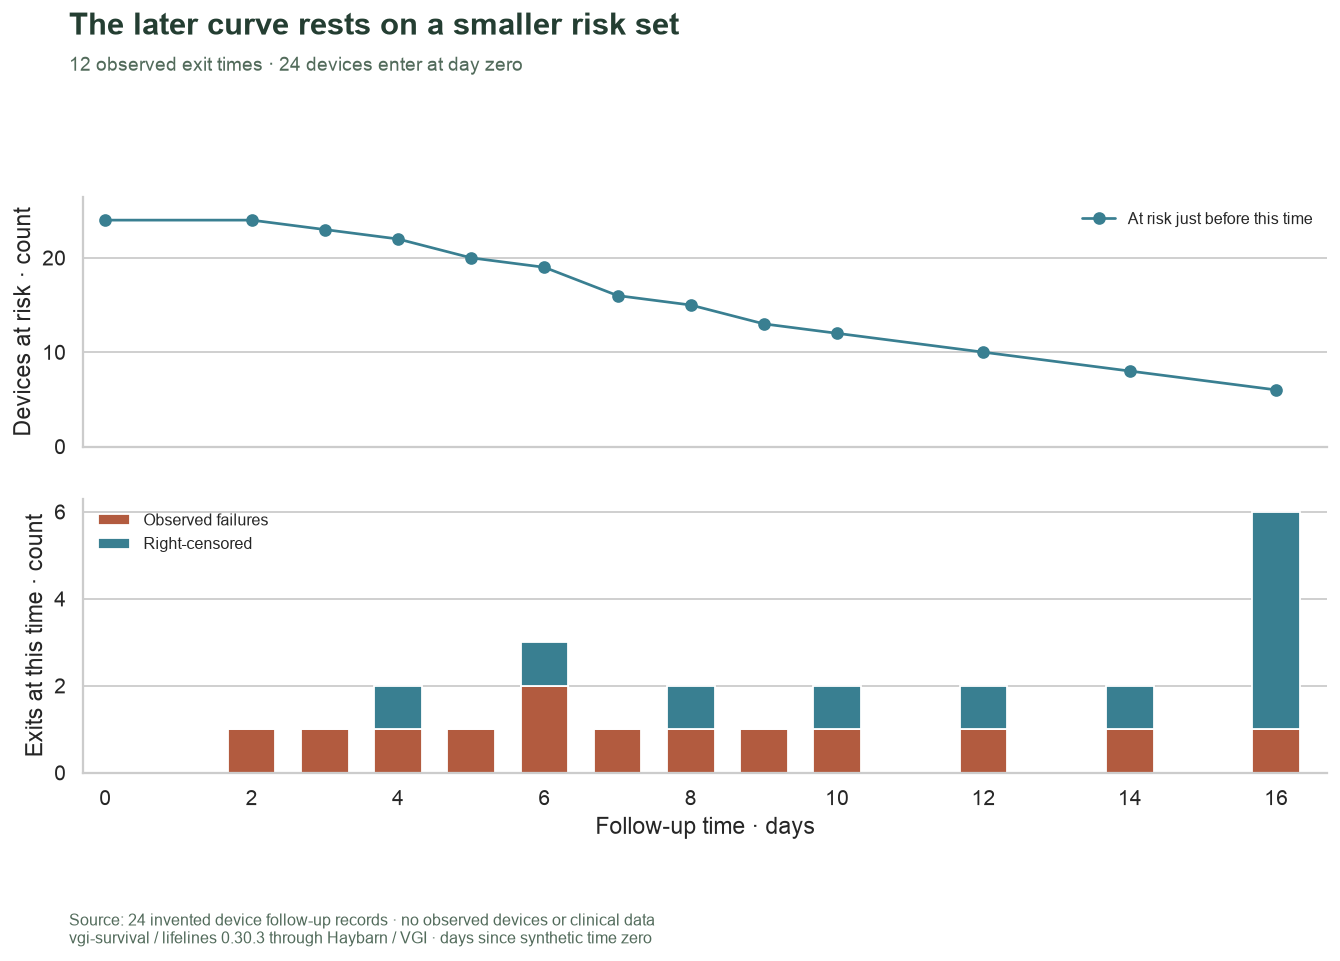

In [11]:
fig, (risk_ax, exit_ax) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
risk_ax.plot(curve.time, curve.at_risk_sql, "o-", color="#397f91", label="At risk just before this time")
risk_ax.set(ylabel="Devices at risk · count", ylim=(0, float(curve.at_risk_sql.max()) * 1.1))
risk_ax.legend(loc="upper right", frameon=False, fontsize=9)
exits = curve.loc[curve.time > 0]
exit_ax.bar(exits.time, exits.failures, width=0.65, color="#b25b3f", label="Observed failures")
exit_ax.bar(exits.time, exits.censored, bottom=exits.failures, width=0.65, color="#397f91", label="Right-censored")
exit_ax.set(xlabel="Follow-up time · days", ylabel="Exits at this time · count", xlim=(-0.3, FOLLOWUP_DAYS + 0.7))
exit_ax.legend(loc="upper left", frameon=False, fontsize=9)
for ax in (risk_ax, exit_ax):
    ax.grid(axis="x", visible=False)
finish(
    fig,
    f"risk-sets-{FOLLOWUP_DAYS}",
    "The later curve rests on a smaller risk set",
    f"{len(curve) - 1} observed exit times · {int(availability.iloc[0].devices)} devices enter at day zero",
)

In [12]:
a = availability.iloc[0]
last = curve.iloc[-1]
m = float(median.iloc[0].median_survival)
median_sentence = (
    f"The estimated median is **{m:g} days**, the first time the curve reaches or falls below 0.5."
    if math.isfinite(m)
    else (
        "The estimated median is **unreached**: the worker returns `inf` because the curve never reaches "
        "0.5 in observed follow-up. This does not mean devices last forever."
    )
)
display(
    Markdown(
        f"With follow-up ending at **{FOLLOWUP_DAYS} days**, **{int(a.observed_failures)} failures** are observed and "
        f"**{int(a.censored)} devices are censored**. "
        f"At day **{last.time:g}**, Kaplan–Meier is **{last.survival:.3f}**, "
        f"while the original-denominator fraction is **{last.original_denominator:.3f}**. "
        f"The last risk-set size is **{int(last.at_risk_sql)}**. " + median_sentence
    )
)

With follow-up ending at **16 days**, **13 failures** are observed and **11 devices are censored**. At day **16**, Kaplan–Meier is **0.361**, while the original-denominator fraction is **0.458**. The last risk-set size is **6**. The estimated median is **12 days**, the first time the curve reaches or falls below 0.5.

## Check the relationships, including an unreached median

These checks verify the event coding, cutoff boundary, risk sets, exact exit counts, numerical agreement, monotonicity, confidence-bound ordering and median semantics. A finite median must equal the first half-survival crossing; an infinite median must accompany no crossing. No check demands a particular numerical estimate.

In [13]:
%%sql checks <<
SELECT 'device identities are unique and preserved' AS check_name,
 (SELECT count(*)=count(DISTINCT device_id) AND count(*)=(SELECT count(*) FROM recorded) FROM cohort) AS passed
UNION ALL SELECT 'event coding and durations are valid',
 (SELECT bool_and(event IN (0,1) AND duration_days>0 AND duration_days<={{ FOLLOWUP_DAYS }}) FROM cohort)
UNION ALL SELECT 'late recorded outcomes become censored at cutoff',
 (SELECT coalesce(bool_and(duration_days={{ FOLLOWUP_DAYS }} AND event=0),true)
 FROM cohort WHERE administratively_shortened)
UNION ALL SELECT 'all devices exit exactly once',(SELECT sum(failures+censored)=(SELECT count(*) FROM cohort) FROM event_table)
UNION ALL SELECT 'events never exceed the risk set',(SELECT bool_and(failures+censored<=at_risk_sql) FROM event_table)
UNION ALL SELECT 'worker and SQL risk sets agree',(SELECT bool_and(at_risk=at_risk_sql) FROM comparison)
UNION ALL SELECT 'worker and SQL product-limit estimates agree',
 (SELECT bool_and(abs(survival-survival_sql)<1e-10) FROM comparison)
UNION ALL SELECT 'survival starts at one',(SELECT time=0 AND abs(survival-1)<1e-12 FROM km ORDER BY time LIMIT 1)
UNION ALL SELECT 'survival is bounded and nonincreasing',
 (SELECT bool_and(survival BETWEEN 0 AND 1 AND (previous IS NULL OR survival<=previous+1e-12))
 FROM(SELECT *,lag(survival) OVER(ORDER BY time) AS previous FROM km))
UNION ALL SELECT 'pointwise confidence bounds contain the estimate',
 (SELECT bool_and(ci_lower>=0 AND ci_upper<=1 AND ci_lower<=survival+1e-12 AND ci_upper>=survival-1e-12) FROM km)
UNION ALL SELECT 'median agrees with half-survival crossing',
 (SELECT median_survival=first_half_crossing FROM median_check)
UNION ALL SELECT 'original-denominator comparator is not below Kaplan Meier',
 (SELECT bool_and(original_denominator+1e-12>=survival) FROM comparison);

In [14]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert int(a.devices) == manifest["rows"]
display(Markdown(f"**{len(checks)} SQL checks passed**, plus fixture hash and cohort-size checks."))

,check_name,passed
0,device identities are unique and preserved,True
1,event coding and durations are valid,True
2,late recorded outcomes become censored at cutoff,True
3,all devices exit exactly once,True
4,events never exceed the risk set,True
5,worker and SQL risk sets agree,True
6,worker and SQL product-limit estimates agree,True
7,survival starts at one,True
8,survival is bounded and nonincreasing,True
9,pointwise confidence bounds contain the estimate,True


**12 SQL checks passed**, plus fixture hash and cohort-size checks.

## Focused experiment: stop observation earlier

Change only **`FOLLOWUP_DAYS` from 16 to 8**, restart and run all. Predict fewer observed failures and more administrative censoring. Compare the curve only over the shared 0–8 day interval: events through day 8 and their starting risk sets should agree with the longer run. After day 8, the shorter run provides no survival estimate.

Inspect whether the median remains estimable, and compare `inf` with the saved finite/unreached result without replacing infinity with zero or the cutoff. This changes the observation window, not the latent failure process. The hand-authored fixture cannot validate independent censoring. Restore **16** for the baseline; the README saves the shorter run separately.

In [15]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>